# ACE2 — Intermediate Downscaling Inference

**Stage 1 of 2** in the DeepRisk climate-downscaling pipeline.

This notebook takes raw **ACE2** climate fields at **180 x 360 (~1 deg)** and produces a
global **720 x 1440** "intermediate" field using an **EDM diffusion model with posterior
(likelihood-guided) sampling**. The five channels are
`[temperature, specific_humidity, u_wind, v_wind, precipitation]`.

```
ACE2 (180x360)  --normalize-->  EDM posterior sampling  -->  (720x1440)  --un-standardize-->  intermediate NetCDF
```

The output of this notebook is the **input** to the *ACE2 — Regional Downscaling*
notebook (Stage 2).

> **Fidelity:** every code cell below is copied from the verified pipeline
> (`run_ace_pipeline.py` / `core/` for LUCIE). Only the
> markdown and the final plots are new — the numerics are unchanged. Sampling uses a fixed
> seed (`17`), so results are deterministic and reproducible.

## 1. Configuration

Everything you might want to change lives here: the input file (a 10-timestep sample shipped
with the repo), the output directory, and the model checkpoints (vendored inside the repo
under `models/01-global/`). Edit `OUTPUT_DIR` to point wherever you like.

In [ ]:
# --- paths you may want to edit -------------------------------------------------
import os
INPUT_FILE = "<DEEPRISK_ROOT>/notebooks/sample_data/ace2/ACE_era5_sst+0K_sample10.nc"
OUTPUT_DIR = "<OUTPUT_DIR>/ace2/intermediate"
N_SAMPLES  = 10              # number of timesteps to downscale
SOURCE     = "ACE2"

# --- model artifacts (vendored in-repo) ----------------------------------------
EDM_CHECKPOINT     = "<DEEPRISK_ROOT>/models/01-global/checkpoints/checkpoint-007862.pt"
EDM_CONDITION_PATH = "<DEEPRISK_ROOT>/models/01-global/condition.npy"
NORM_MEAN_PATH     = "<DEEPRISK_ROOT>/models/01-global/stats/normalize_mean.npz"
NORM_STD_PATH      = "<DEEPRISK_ROOT>/models/01-global/stats/normalize_std.npz"

os.makedirs(OUTPUT_DIR, exist_ok=True)
print("Input :", INPUT_FILE)
print("Output:", OUTPUT_DIR)

Input : <DEEPRISK_ROOT>/notebooks/sample_data/ace2/ACE_era5_sst+0K_sample10.nc
Output: <OUTPUT_DIR>/ace2/intermediate


## 2. Imports

The EDM network class lives in the external **`arrgen`** package — the one documented
external dependency of this repo (see the README *Prerequisites* section).

In [2]:
import sys, os, time, warnings
import numpy as np
import torch
import torch.nn.functional as F
import xarray as xr
import pandas as pd

# The EDM model is defined in the `arrgen` package vendored at models/01-global/arrgen (the verified
# reference implementation). It is the one documented external prerequisite —
# see README "Prerequisites".
import os; sys.path.insert(0, os.path.abspath(os.path.join(os.getcwd(), "..", "models", "01-global")))  # vendored arrgen
from hydra.utils import instantiate
from omegaconf import OmegaConf
from arrgen.generating.diffusion import PosteriorDiffusionSampler
from arrgen.generating.conditioning_methods import SuperResolutionOperator, ConditioningMethod

warnings.filterwarnings("ignore")
print("torch", torch.__version__, "| CUDA available:", torch.cuda.is_available())


torch 2.7.1+cu128 | CUDA available: True


## 3. The EDM posterior sampler

EDM (Elucidating Diffusion Model) generates the 720x1440 field by iteratively denoising
Gaussian noise. **Posterior sampling** adds a likelihood term at every step so the result
stays consistent with the low-resolution ACE2 *measurement* — this is what makes it a
*downscaler* rather than an unconditional generator.

The only source-specific knob is the `SuperResolutionOperator`'s `in_shape`, which equals the
ACE2 grid **(180, 360)**. (LUCIE 48x96, ACE2 180x360, CESM 192x288 — everything else,
including the seed and the 35-step schedule, is identical across sources.)

In [ ]:
class EDMPosteriorSampler(PosteriorDiffusionSampler):
    """ACE2 posterior sampler: measurement (180, 360) -> output (720, 1440)."""
    def __init__(self, net):
        # NB: we do NOT call super().__init__() — we set the source-specific in_shape directly.
        self.net = net
        self.sr = SuperResolutionOperator(in_shape=(180, 360), target_shape=(720, 1440))
        self.cm = ConditioningMethod(self.sr)


class EDMSampler(torch.nn.Module):
    """Wraps the network + posterior sampler + a fixed-seed generator (seed=17)."""
    def __init__(self, net, device, orography_condition):
        super().__init__()
        self.net = net
        self.posterior = EDMPosteriorSampler(net)
        self.generator = torch.Generator(device=device).manual_seed(17)
        self.device = device
        self.condition = orography_condition

    def forward(self, measurement):
        # measurement: [B, 5, 180, 360]
        assert measurement.shape[-2:] == (180, 360), measurement.shape
        condn = self.condition.expand(measurement.shape[0], -1, -1, -1)
        return self.posterior.pos_edm_sampler(
            latents=torch.randn((measurement.shape[0], measurement.shape[1], 720, 1440),
                                generator=self.generator, device=self.device),
            condition=condn, measurement=measurement,
            num_steps=35, sigma_min=0.001, sigma_max=200, rho=7,
            S_churn=200, S_min=0.01, S_max=20, S_noise=1,
        )

## 4. Normalization & (de)standardization

The model works in a standardized space. Precipitation additionally gets a log-transform
(it is highly skewed). These are the exact constants from training (`ERA5SR.py`).

In [4]:
# EDM normalization variable order (must match training). The last channel
# (geopotential) is a stats-only placeholder and is dropped — the model has 5
# channels: [temperature, specific_humidity, u_wind, v_wind, precipitation].
NORM_VARIABLES = [
    "2m_temperature", "specific_humidity_133", "u_component_of_wind_83",
    "v_component_of_wind_83", "total_precipitation_6hr", "geopotential_at_surface",
]

def load_norm_stats():
    means_data = np.load(NORM_MEAN_PATH)
    stds_data  = np.load(NORM_STD_PATH)
    means = np.stack([means_data[v] for v in NORM_VARIABLES], axis=0).reshape(-1, 1, 1)
    stds  = np.stack([stds_data[v]  for v in NORM_VARIABLES], axis=0).reshape(-1, 1, 1)
    # Precipitation stats are overridden to the log-space values used in training (ERA5SR.py)
    means[-2] = 1.0973763
    stds[-2]  = 1.1307881
    means = means[:-1]   # drop geopotential -> [5, 1, 1]
    stds  = stds[:-1]
    return means, stds

def preprocess_for_edm(data, means, stds):
    """Log-transform precipitation, then standardize all channels."""
    data = data.copy()
    data[-1] = np.log(np.clip(data[-1], 1e-10, 1e10) / 1.1e-4 + 1) + 0.17   # log precip
    data = (data - means) / stds
    return data.astype(np.float32)

def unstandardize(x, means, stds):
    """Inverse of preprocess: de-standardize, then invert the precip log-transform."""
    x = x * stds.reshape(-1, 1, 1) + means.reshape(-1, 1, 1)
    x[-1] = (np.exp(x[-1] - 0.17) - 1) * 1.1e-4
    return x

means, stds = load_norm_stats()
print("Normalization stats loaded. precip(log-space) mean=%.4f std=%.4f" % (means[-1,0,0], stds[-1,0,0]))


Normalization stats loaded. precip(log-space) mean=1.0974 std=1.1308


## 5. Build the model

In [ ]:
def load_edm_model(device):
    """Build the EDM (Elucidating Diffusion Model) network, load EMA weights, and
    attach the orography condition. Architecture matches the training config exactly."""
    model_cfg = OmegaConf.create({
        '_target_': 'arrgen.models.precond.EDMPrecond',
        'img_resolution': (720, 1440), 'img_channels': 5, 'condition_channels': 1,
        'sigma_min': 0, 'sigma_max': 80, 'sigma_data': 1,
        'model': {
            '_target_': 'arrgen.models.unet_sr.UNet',
            'img_resolution': (720, 1440), 'in_channels': 6, 'out_channels': 5,
            'inner_channel': 32, 'norm_groups': 32, 'channel_mults': [1, 2, 4, 8, 16],
            'attn_res': [], 'res_blocks': 3, 'dropout': 0,
            'with_noise_level_emb': True, 'auxilary_dim': 0, 'use_checkpoint': True,
        },
    })
    net = instantiate(model_cfg, _recursive_=False, _convert_="object")
    net.load_state_dict(torch.load(EDM_CHECKPOINT, map_location="cpu", weights_only=True)["ema"])
    net.to(device)

    orography = torch.tensor(np.load(EDM_CONDITION_PATH)[0:1]).float().to(device)  # (1, 1, 720, 1440)
    assert orography.shape == (1, 1, 720, 1440), orography.shape

    sampler = EDMSampler(net, device, orography)
    print("EDM model + orography condition loaded.")
    return sampler


## 6. Load the ACE2 input data

We read the 10-timestep sample shipped with the repo, map its variables onto the 5 model
channels, apply any unit conversions, and **flip latitude to North-to-South** (the
orientation the EDM was trained on).

In [ ]:
# Verbatim from run_ace_pipeline.py:load_ace_sample.
ACE_VARIABLES = {
    'temperature': 'TMP2m',
    'specific_humidity': 'specific_total_water_7',
    'u_wind': 'eastward_wind_3',
    'v_wind': 'northward_wind_3',
    'precipitation': 'PRATEsfc',
}

def load_source_sample(ds, idx):
    """Return one ACE2 timestep as (5, 180, 360), physical units, North-to-South."""
    temperature       = ds[ACE_VARIABLES['temperature']].isel(sample=0, time=idx).values   # [180, 360]
    specific_humidity = ds[ACE_VARIABLES['specific_humidity']].isel(sample=0, time=idx).values
    u_wind            = ds[ACE_VARIABLES['u_wind']].isel(sample=0, time=idx).values
    v_wind            = ds[ACE_VARIABLES['v_wind']].isel(sample=0, time=idx).values
    precipitation     = ds[ACE_VARIABLES['precipitation']].isel(sample=0, time=idx).values

    # Convert precipitation rate (kg/m^2/s) -> 6-hour accumulation (m)
    precipitation = precipitation * 6.0 * 3600.0 / 1000.0

    data = np.stack([temperature, specific_humidity, u_wind, v_wind, precipitation], axis=0)  # [5, 180, 360]
    assert data.shape == (5, 180, 360), f"ACE shape mismatch: {data.shape}"

    # Flip latitude: South-to-North (ACE native) -> North-to-South (EDM convention)
    data = np.flip(data, axis=1).copy()
    return data


## 7. Run the downscaling loop

For each of the ACE2 timesteps: preprocess -> EDM posterior sampling -> un-standardize ->
save as `sample_NNNNNN_intermediate.nc` (720x1440, gzip-compressed, lat ascending South->North
for NetCDF convention). On a modern GPU each sample takes ~10-15 s.

In [7]:
def save_intermediate(edm_output_physical, timestamp, sample_idx, output_dir):
    """Save the global EDM output (flip back to South->North for NetCDF convention)."""
    global_lat = np.linspace(-90, 90, 720)
    global_lon = np.linspace(0, 360, 1440)
    try:
        time_coord = [pd.Timestamp(timestamp)]
    except Exception:
        time_coord = [pd.Timestamp(str(timestamp))]
    flipped = np.flipud
    ds = xr.Dataset({
        'temperature':         (['time', 'lat', 'lon'], flipped(edm_output_physical[0]).reshape(1, 720, 1440)),
        'specific_humidity':   (['time', 'lat', 'lon'], flipped(edm_output_physical[1]).reshape(1, 720, 1440)),
        'u_component_of_wind': (['time', 'lat', 'lon'], flipped(edm_output_physical[2]).reshape(1, 720, 1440)),
        'v_component_of_wind': (['time', 'lat', 'lon'], flipped(edm_output_physical[3]).reshape(1, 720, 1440)),
        'tp6hr':               (['time', 'lat', 'lon'], flipped(edm_output_physical[4]).reshape(1, 720, 1440)),
    }, coords={'time': time_coord, 'lat': global_lat, 'lon': global_lon})
    ds.attrs['source'] = 'ACE2 EDM intermediate output'
    ds.attrs['model_resolution'] = '720x1440'
    enc = {v: {'zlib': True, 'complevel': 4, 'chunksizes': (1, 180, 360)} for v in ds.data_vars}
    enc['time'] = {'units': 'days since 1900-01-01'}
    fname = os.path.join(output_dir, f"sample_{sample_idx:06d}_intermediate.nc")
    ds.to_netcdf(fname, encoding=enc)
    return fname


assert torch.cuda.is_available(), "This notebook needs a GPU (set CUDA_VISIBLE_DEVICES)."
device = torch.device("cuda")

ds_in = xr.open_dataset(INPUT_FILE)
time_values = ds_in.valid_time.values.squeeze(axis=0) if 'valid_time' in ds_in else ds_in.time.values
edm_sampler = load_edm_model(device)

for idx in range(N_SAMPLES):
    t0 = time.time()
    raw  = load_source_sample(ds_in, idx)                 # [5, 180, 360] physical, N->S
    norm = preprocess_for_edm(raw, means, stds)           # standardized
    measurement = torch.from_numpy(norm).float().unsqueeze(0).to(device)   # [1, 5, 180, 360]
    edm_output  = edm_sampler(measurement)                # [1, 5, 720, 1440]
    edm_phys    = unstandardize(edm_output.detach().cpu().numpy()[0], means, stds)
    fname = save_intermediate(edm_phys, time_values[idx], idx, OUTPUT_DIR)
    del measurement, edm_output; torch.cuda.empty_cache()
    print(f"  sample {idx}: {time.time()-t0:.1f}s -> {os.path.basename(fname)}")
ds_in.close()
print("Done. Intermediate files written to", OUTPUT_DIR)

EDM model + orography condition loaded.
  sample 0: 11.6s -> sample_000000_intermediate.nc
  sample 1: 10.7s -> sample_000001_intermediate.nc
  sample 2: 10.8s -> sample_000002_intermediate.nc
  sample 3: 10.7s -> sample_000003_intermediate.nc
  sample 4: 10.9s -> sample_000004_intermediate.nc
  sample 5: 10.7s -> sample_000005_intermediate.nc
  sample 6: 10.9s -> sample_000006_intermediate.nc
  sample 7: 10.7s -> sample_000007_intermediate.nc
  sample 8: 10.8s -> sample_000008_intermediate.nc
  sample 9: 10.8s -> sample_000009_intermediate.nc
Done. Intermediate files written to <OUTPUT_DIR>/ace2/intermediate


## 8. Visualize

Maps and value distributions for the first sample, styled to match the project's standard
analysis figures (`sst_analysis_2015_2022`).

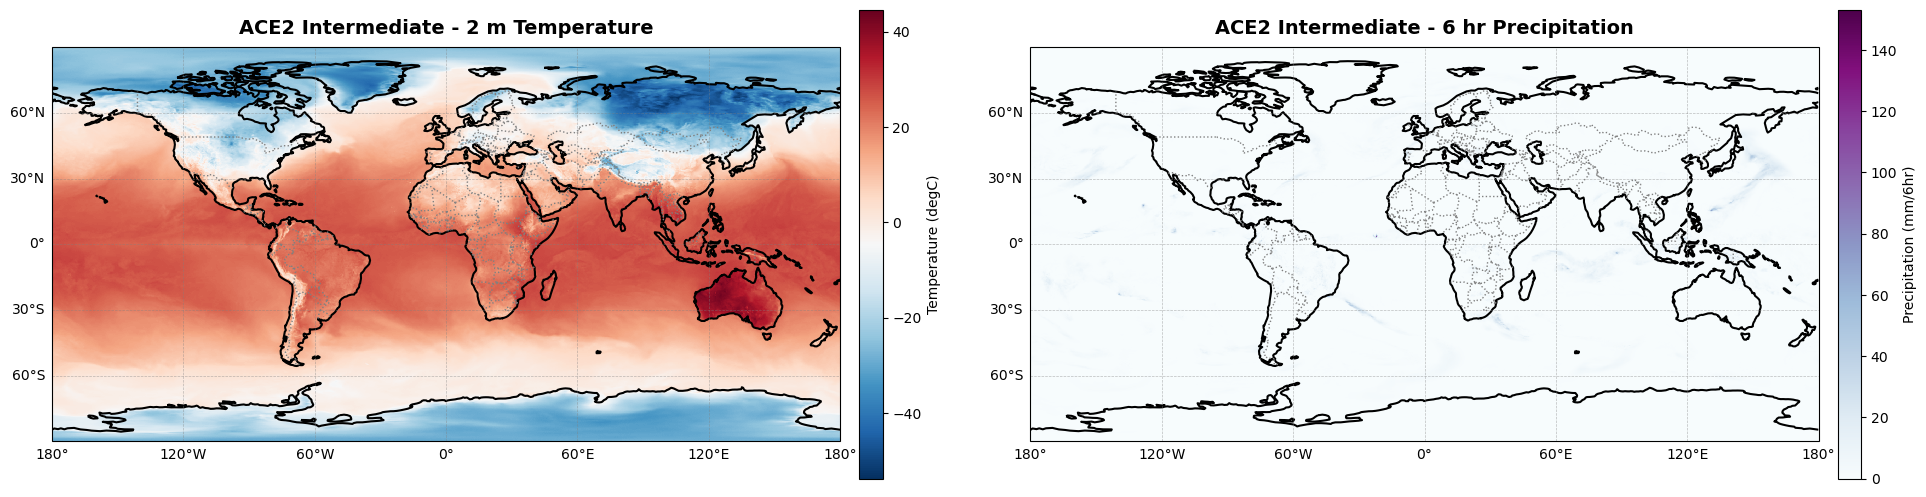

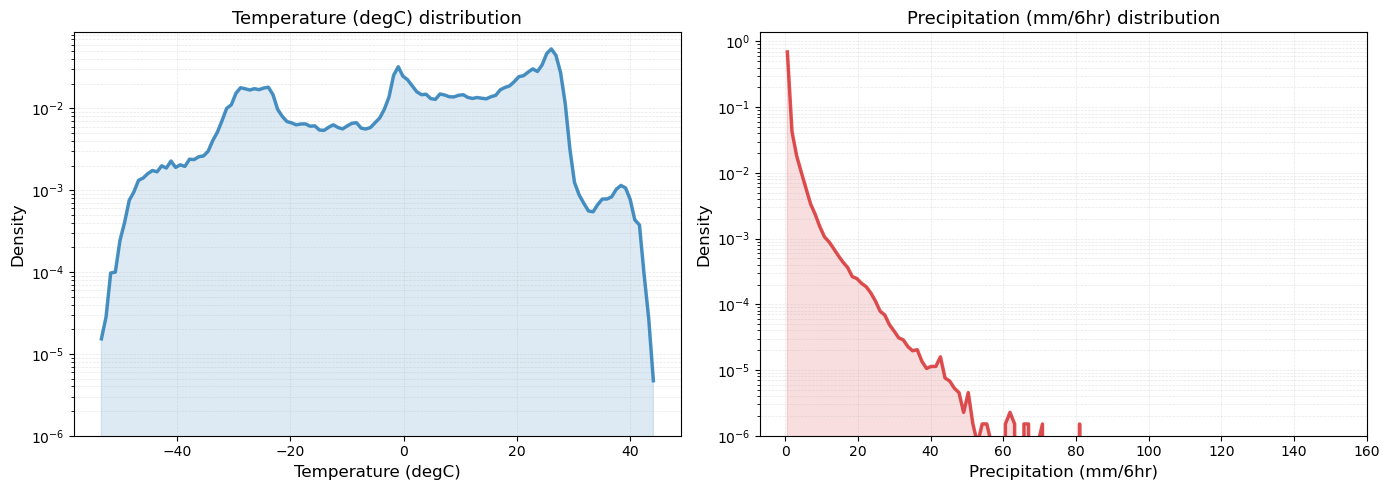

In [8]:
# Visualization in the style of <SCRATCH>:
#   cartopy PlateCarree, pcolormesh, RdBu_r for temperature, BuPu for precip,
#   coastlines + borders, labeled gridlines, 300-dpi save.
import matplotlib.pyplot as plt
import cartopy.crs as ccrs
import cartopy.feature as cfeature

ds_show = xr.open_dataset(os.path.join(OUTPUT_DIR, "sample_000000_intermediate.nc"))
lon = ds_show.lon.values
lat = ds_show.lat.values
temp = ds_show['temperature'].isel(time=0).values - 273.15       # K -> degC
precip = ds_show['tp6hr'].isel(time=0).values * 1000.0           # m -> mm (6hr)

fig = plt.figure(figsize=(20, 7))
for i, (field, cmap, label, title) in enumerate([
        (temp,   'RdBu_r', 'Temperature (degC)',      f'{SOURCE} Intermediate - 2 m Temperature'),
        (precip, 'BuPu',   'Precipitation (mm/6hr)',  f'{SOURCE} Intermediate - 6 hr Precipitation')]):
    ax = fig.add_subplot(1, 2, i + 1, projection=ccrs.PlateCarree())
    im = ax.pcolormesh(lon, lat, field, cmap=cmap, transform=ccrs.PlateCarree(), shading='auto')
    ax.add_feature(cfeature.COASTLINE, linewidth=1.5, edgecolor='black')
    ax.add_feature(cfeature.BORDERS, linewidth=1, edgecolor='gray', linestyle=':')
    gl = ax.gridlines(draw_labels=True, linewidth=0.5, color='gray', alpha=0.5, linestyle='--')
    gl.top_labels = gl.right_labels = False
    cbar = plt.colorbar(im, ax=ax, label=label, shrink=0.7, pad=0.02)
    ax.set_title(title, fontsize=14, fontweight='bold', pad=10)
plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR, "intermediate_maps_sample0.png"), dpi=300, bbox_inches='tight')
plt.show()

# Distribution plot (log-y), matching the PDF panels of the reference analysis.
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for ax, data, c, lbl in [(axes[0], temp.ravel(), '#1f77b4', 'Temperature (degC)'),
                         (axes[1], precip.ravel(), '#d62728', 'Precipitation (mm/6hr)')]:
    counts, edges = np.histogram(data, bins=120, density=True)
    centers = 0.5 * (edges[:-1] + edges[1:])
    ax.plot(centers, counts, linewidth=2.5, alpha=0.8, color=c)
    ax.fill_between(centers, counts, alpha=0.15, color=c)
    ax.set_yscale('log'); ax.set_ylim(bottom=1e-6)
    ax.set_xlabel(lbl, fontsize=12); ax.set_ylabel('Density', fontsize=12)
    ax.grid(True, alpha=0.3, which='both', linestyle='--', linewidth=0.5)
    ax.set_title(f'{lbl} distribution', fontsize=13)
plt.tight_layout(); plt.show()
ds_show.close()


## Next step

The `sample_*_intermediate.nc` files in `<OUTPUT_DIR>/ace2/intermediate` are the input
to **ACE2 — Regional Downscaling**, which refines the CONUS region to 960x1560.